<h1 style="text-align: center;">Programa10.EvaluacionRegresion</h1>
<p style="text-align: center;">22-11-2026</p>
<p style="text-align: center;">
    <img src="img/ITQ.png" width="500">
</p>

**Nombre:** Nikolay Misael De La Cruz Melendres  
**Asignatura:** Fundamentos de Machine Learning  
**Docente:** Elvis David Pachacama Cabezas  
**Repositorio:** [NikolayDlc/fundamentosMachine](https://github.com/NikolayDlc/fundamentosMachine)

---

## Objetivo de la práctica

Comprender cómo entrenar y evaluar un modelo de regresión utilizando el conjunto de datos Diabetes de scikit-learn, mediante la división Hold-Out, la estandarización, la validación cruzada y las métricas MAE, RMSE y MAPE.

## Metodología

Se utilizará el aprendizaje supervisado para estimar una variable objetivo numérica a partir de características médicas.

El procedimiento comprende:

1. Carga y exploración del dataset.
2. Extracción de las variables X e y.
3. División en entrenamiento y test.
4. Estandarización de los datos.
5. Definición de métricas de evaluación.
6. Construcción del algoritmo SVR.
7. Validación cruzada mediante KFold.
8. Entrenamiento y evaluación final.
9. Comparación gráfica de predicciones y valores reales.

**Dataset:** Diabetes de scikit-learn (442 observaciones, 10 características).

**Tipo de problema:** Regresión supervisada.

## 1. Comprensión del problema y de los datos

En este programa se utiliza el dataset Diabetes de scikit-learn, que contiene 442 observaciones de pacientes y 10 características médicas.

**Objetivo:** utilizar aprendizaje supervisado para predecir una medida cuantitativa de progresión de la diabetes un año después de las mediciones iniciales.

**Tipo de problema:** regresión, porque la variable objetivo es numérica y no una categoría.

**Metodología:** se utilizará una división Hold-Out del 80 % para entrenamiento y 20 % para prueba. Después se aplicarán estandarización, validación cruzada KFold y evaluación mediante MAE, RMSE y MAPE.

Este ejercicio tiene fines académicos; sus resultados no constituyen predicciones clínicas validadas.

In [1]:
import numpy as np
from math import sqrt
from pprint import pprint
from sklearn import datasets
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.model_selection import KFold
from sklearn.metrics import make_scorer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
from sklearn import preprocessing

In [2]:
# Cargar y explorar los datos
datos = datasets.load_diabetes()
pprint(datos)
print(np.shape(datos.data))

{'DESCR': '.. _diabetes_dataset:\n'
          '\n'
          'Diabetes dataset\n'
          '----------------\n'
          '\n'
          'Ten baseline variables, age, sex, body mass index, average blood\n'
          'pressure, and six blood serum measurements were obtained for each '
          'of n =\n'
          '442 diabetes patients, as well as the response of interest, a\n'
          'quantitative measure of disease progression one year after '
          'baseline.\n'
          '\n'
          '**Data Set Characteristics:**\n'
          '\n'
          ':Number of Instances: 442\n'
          '\n'
          ':Number of Attributes: First 10 columns are numeric predictive '
          'values\n'
          '\n'
          ':Target: Column 11 is a quantitative measure of disease progression '
          'one year after baseline\n'
          '\n'
          ':Attribute Information:\n'
          '    - age     age in years\n'
          '    - sex\n'
          '    - bmi     body mass index\n'

## 2. Extracción de características y variable objetivo

En aprendizaje supervisado trabajamos con dos elementos:

- **X:** matriz de características utilizadas como entradas del modelo.
- **y:** variable objetivo que el modelo debe aprender a predecir.

En el dataset Diabetes, X contiene las diez características médicas, mientras que y contiene la medida cuantitativa de progresión de la enfermedad.

No debemos confundir X con y: el modelo aprende a estimar y a partir de X.

In [3]:
# Extraer la matriz de datos "X" y la variable target "y"
X = datos.data
y = datos.target

In [4]:
# Partición EXTERNA: hold-out split 80% train - 20% test.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (353, 10)
X_test: (89, 10)
y_train: (353,)
y_test: (89,)


In [5]:
# Conservar los datos sin la estandarización adicional
# para realizar validación cruzada correctamente.
X_train_original = X_train.copy()
X_test_original = X_test.copy()

# Estandarización para el entrenamiento y test finales
standardizer = preprocessing.StandardScaler()

X_train = standardizer.fit_transform(X_train)
X_test = standardizer.transform(X_test)

print("Entrenamiento estandarizado:", X_train.shape)
print("Test estandarizado:", X_test.shape)

Entrenamiento estandarizado: (353, 10)
Test estandarizado: (89, 10)


## 3. Métricas para evaluar la regresión

Como el modelo predice números, se utilizan métricas que miden la diferencia entre valores reales y predichos.

**MAE (Mean Absolute Error):** media de los errores absolutos. Indica cuánto se alejan las predicciones de los valores reales, en promedio.

**RMSE (Root Mean Squared Error):** raíz del error cuadrático medio. Penaliza especialmente los errores grandes.

**MAPE (Mean Absolute Percentage Error):** calcula el error porcentual absoluto medio respecto a los valores reales.

En estas tres métricas, un valor más bajo indica menor error.

Scikit-learn utiliza puntuaciones negativas para algunas métricas cuando realiza validación cruzada, porque su sistema de evaluación busca maximizar las puntuaciones.

In [6]:
# Métricas de evaluación.
metricas = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': make_scorer(
        lambda y, y_pred:
        sqrt(mean_squared_error(y, y_pred)),
        greater_is_better=False
    ),
    'MAPE': make_scorer(
        lambda y, y_pred:
        np.mean(np.abs((y - y_pred) / y)) * 100,
        greater_is_better=False
    )
}

In [7]:
# Definimos un algoritmo SVM de regresión
alg = SVR(C=10, gamma='scale', kernel='rbf')

print(alg)

SVR(C=10)


In [8]:
# Validación cruzada interna KFold con cinco particiones.
# El escalador se ajusta dentro de cada entrenamiento interno.

from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('estandarizador', preprocessing.StandardScaler()),
    ('modelo', SVR(C=10, gamma='scale', kernel='rbf'))
])

results = cross_validate(
    pipeline,
    X_train_original,
    y_train,
    cv=KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring=metricas
)

In [9]:
# Presentación de los resultados de la evaluación.
pprint(results)

{'fit_time': array([0.00371385, 0.00261331, 0.00264359, 0.00267553, 0.00264406]),
 'score_time': array([0.00150847, 0.00118804, 0.00117373, 0.00131369, 0.00114202]),
 'test_MAE': array([-48.26285616, -51.99094138, -42.19909846, -45.73437715,
       -50.39789838]),
 'test_MAPE': array([-32.83110657, -45.90028442, -37.74947192, -43.12401136,
       -44.16570536]),
 'test_RMSE': array([-57.68310314, -60.27338482, -51.94585761, -55.51382769,
       -63.98279561])}


In [10]:
# Promedio de los errores de los cinco pliegues
print("MAE promedio:", -np.mean(results['test_MAE']))
print("RMSE promedio:", -np.mean(results['test_RMSE']))
print("MAPE promedio (%):", -np.mean(results['test_MAPE']))

MAE promedio: 47.717034307581784
RMSE promedio: 57.879793772651354
MAPE promedio (%): 40.75411592773147


In [11]:
# Entrenamiento final con todos los datos de entrenamiento externo.
# La configuración del SVR ya fue evaluada mediante KFold.
# No se realizó una búsqueda automática de hiperparámetros.

model = SVR(C=10, gamma='scale', kernel='rbf')
model = model.fit(X_train, y_train)

In [12]:
# Extraemos el error absoluto promedio (MAE) del conjunto de test
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

print('Test results (MAE): ', mae)

Test results (MAE):  41.319671295107455


In [13]:
# Comparar las primeras 10 predicciones con los valores reales

print('Predicciones:   ', np.round(y_pred[:10], 1))
print('Valores reales: ', y_test[:10])

Predicciones:    [149.  172.2 152.9 212.3 110.1 122.3 227.3 191.8 106.7 103.9]
Valores reales:  [219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]


## 4. Comparación gráfica: valores reales y predichos

Se utiliza un diagrama de dispersión para analizar visualmente el comportamiento del modelo de regresión.

- **Eje X:** valores reales de progresión de la enfermedad.
- **Eje Y:** valores predichos por el modelo SVR.
- **Línea diagonal:** representa las predicciones perfectas, donde el valor real coincide con el predicho.

Los puntos cercanos a la diagonal representan predicciones con menor error absoluto. Los puntos alejados muestran mayores diferencias entre los valores reales y predichos.

Esta gráfica complementa las métricas MAE, RMSE y MAPE.

In [14]:
# Gráfica de valores reales frente a predicciones

def grafica_real_vs_pred(y_true, y_pred, metricas, algoritmo):
    fig, ax = plt.subplots()

    ax.scatter(y_true, y_pred, edgecolors=(0, 0, 0))

    ax.plot(
        [y_true.min(), y_true.max()],
        [y_true.min(), y_true.max()],
        'k--',
        lw=4
    )

    ax.set_xlabel('Valor real de progresión')
    ax.set_ylabel('Predicción')

    plt.show()

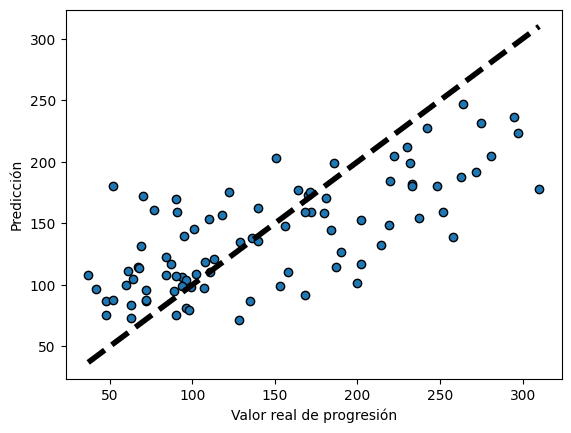

In [15]:
# Mostrar la gráfica del modelo de regresión
grafica_real_vs_pred(y_test, y_pred, metricas, model)

In [16]:
# Evaluación final del modelo con las tres métricas

rmse_test = sqrt(mean_squared_error(y_test, y_pred))
mape_test = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print("MAE de test:", mae)
print("RMSE de test:", rmse_test)
print("MAPE de test (%):", mape_test)

MAE de test: 41.319671295107455
RMSE de test: 51.7917749234879
MAPE de test (%): 36.33911028176271


## Conclusiones

En esta práctica se estudió el funcionamiento de un modelo de regresión supervisada utilizando el dataset Diabetes de scikit-learn.

Se aplicó el método Hold-Out para separar los datos de entrenamiento y prueba, y se utilizó validación cruzada KFold para evaluar el comportamiento del algoritmo SVR en cinco particiones.

Las métricas MAE, RMSE y MAPE permiten cuantificar la diferencia entre los valores reales y las predicciones. La gráfica de dispersión facilita la interpretación visual de los errores.

Se observó que la estandarización debe realizarse cuidadosamente para evitar fuga de información. El uso de Pipeline permite integrar el preprocesamiento dentro del procedimiento de validación cruzada.

Los resultados obtenidos corresponden a un ejercicio académico de evaluación de modelos y no constituyen una herramienta de diagnóstico médico.